# Lab 06 - Sáu bài tập SVM

- **Môn học** Học máy ứng dụng
- **Giảng viên biên soạn** ThS. Nguyễn Thái Anh
- **Sinh viên** Huỳnh Hữu Phúc
- **MSSV** 2474802010314

## Bài tập 1. Tính tay khoảng cách tới ranh giới

Dùng $w_1, w_2, b$ in ra ở mục 2, tự tính $f(x)$ cho hai điểm $(3, 3)$ và $(5, 4.5)$ bằng phép nhân và cộng, không dùng `decision_function`. Khoảng cách từ một điểm tới đường ranh giới bằng $|f(x)| / \sqrt{w_1^2 + w_2^2}$. Tính khoảng cách của hai điểm trên, và của ba vectơ hỗ trợ. Vì sao khoảng cách của ba vectơ hỗ trợ bằng đúng một nửa độ rộng lề?

In [1]:
# -*- coding: utf-8 -*-
"""Bài tập 1: Tính tay khoảng cách tới ranh giới."""
import os
if os.path.basename(os.getcwd()) == "code":
    os.chdir("..")
os.makedirs("figures", exist_ok=True)

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# Tái tạo 24 điểm và mô hình SVM ở Mục 2
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y
svm = SVC(kernel="linear", C=1000).fit(X, y)

# 1. Tính tay từ hệ số in ra ở Mục 2 (w1 = -0.831, w2 = -0.355, b = 4.820)
w1_in, w2_in, b_in = -0.831, -0.355, 4.820
do_dai_w_in = np.sqrt(w1_in ** 2 + w2_in ** 2)
do_rong_le_in = 2 / do_dai_w_in

print("1. TINH TAY VOI HE SO IN RA O MUC 2 (w1=-0.831, w2=-0.355, b=4.820):")
print(f"   Do dai ||w|| = {do_dai_w_in:.4f}, Do rong le = {do_rong_le_in:.4f}")
print(f"   Mot nua do rong le = {do_rong_le_in / 2:.4f}")

hai_diem_moi = [(3.0, 3.0), (5.0, 4.5)]
for x1, x2 in hai_diem_moi:
    fx = w1_in * x1 + w2_in * x2 + b_in
    kc = abs(fx) / do_dai_w_in
    lop_doan = 1 if fx > 0 else 0
    print(f"   Diem ({x1:.1f}, {x2:.1f}): f(x) = {fx:+.3f}, "
          f"khoang cach = {kc:.4f}, doan lop {lop_doan}")
print()

# 2. Tính tay từ hệ số thực của mô hình để đối chiếu chính xác 3 vectơ hỗ trợ
w1, w2 = svm.coef_[0][0], svm.coef_[0][1]
b = svm.intercept_[0]
do_dai_w = np.sqrt(w1 ** 2 + w2 ** 2)
do_rong_le = 2 / do_dai_w

print("2. TINH TAY VOI HE SO CHINH XAC CUA MO HINH:")
for x1, x2 in hai_diem_moi:
    fx = w1 * x1 + w2 * x2 + b
    kc = abs(fx) / do_dai_w
    print(f"   Diem ({x1:.1f}, {x2:.1f}): f(x) = {fx:+.3f}, "
          f"khoang cach = {kc:.4f}")

print("\n   Khoang cach cua 3 vecto ho tro:")
for i in svm.support_:
    x1, x2 = X[i, 0], X[i, 1]
    fx = w1 * x1 + w2 * x2 + b
    kc = abs(fx) / do_dai_w
    print(f"   Vecto HT diem {i:2d} ({x1:.2f}, {x2:.2f}), lop {y[i]}: "
          f"f(x) = {fx:+.3f}, khoang cach = {kc:.4f}")

print(f"\n   Mot nua do rong le = (2 / ||w||) / 2 = 1 / ||w|| = {do_rong_le / 2:.4f}")

1. TINH TAY VOI HE SO IN RA O MUC 2 (w1=-0.831, w2=-0.355, b=4.820):
   Do dai ||w|| = 0.9037, Do rong le = 2.2132
   Mot nua do rong le = 1.1066
   Diem (3.0, 3.0): f(x) = +1.262, khoang cach = 1.3966, doan lop 1
   Diem (5.0, 4.5): f(x) = -0.932, khoang cach = 1.0319, doan lop 0

2. TINH TAY VOI HE SO CHINH XAC CUA MO HINH:
   Diem (3.0, 3.0): f(x) = +1.262, khoang cach = 1.3958
   Diem (5.0, 4.5): f(x) = -0.933, khoang cach = 1.0325

   Khoang cach cua 3 vecto ho tro:
   Vecto HT diem 18 (5.20, 4.22), lop 0: f(x) = -1.000, khoang cach = 1.1064
   Vecto HT diem 10 (2.88, 4.02), lop 1: f(x) = +1.000, khoang cach = 1.1062
   Vecto HT diem 13 (3.59, 2.36), lop 1: f(x) = +1.000, khoang cach = 1.1065

   Mot nua do rong le = (2 / ||w||) / 2 = 1 / ||w|| = 1.1063


**Nhận xét**

Dùng hệ số đã in ở mục 2, $\|w\| = \sqrt{(-0.831)^2 + (-0.355)^2} \approx 0.9037$.

| Điểm | Phép tính $f(x)$ | Khoảng cách $d = \lvert f(x)\rvert/\lVert w\rVert$ |
|---|---|---|
| $(3, 3)$ | $(-0.831)(3) + (-0.355)(3) + 4.820 = 1.2620$ | $1.3966$ |
| $(5, 4.5)$ | $(-0.831)(5) + (-0.355)(4.5) + 4.820 = -0.9325$ | $1.0319$ |

Điểm $(3, 3)$ ở ngoài lề về phía lớp 1. Điểm $(5, 4.5)$ ở trong lề về phía lớp 0.

Với hệ số và toạ độ đầy đủ, khoảng cách của các vectơ hỗ trợ tại chỉ số 18, 10 và 13 lần lượt là $1.1064$, $1.1062$ và $1.1065$. Trên hai mép lề, $f(x) = \pm 1$, nên khoảng cách lý thuyết từ mỗi mép đến đường $f(x)=0$ là $1/\|w\|$, bằng nửa độ rộng lề $2/\|w\|$. Mức này là khoảng $1.1063$. Sai lệch nhỏ giữa ba khoảng cách đến từ nghiệm số của SVM.

## Bài tập 2. Thêm một điểm

Thêm vào 24 điểm của mục 2 một điểm lớp 1 tại $(-1, -1)$, học lại và in $w_1, w_2, b$. Sau đó bỏ điểm đó, thay bằng một điểm lớp 1 tại $(4.5, 4)$, học lại và in lần nữa. Lần nào đường ranh giới thay đổi? Giải thích bằng khái niệm vectơ hỗ trợ.

In [2]:
# -*- coding: utf-8 -*-
"""Bài tập 2: Thêm một điểm và kiểm tra sự thay đổi của đường ranh giới."""
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y

# Mô hình gốc trên 24 điểm
svm_goc = SVC(kernel="linear", C=1000).fit(X, y)
w_goc = svm_goc.coef_[0]
b_goc = svm_goc.intercept_[0]
print("0. Mo hinh goc (24 diem):")
print(f"   w1 = {w_goc[0]:.3f}, w2 = {w_goc[1]:.3f}, b = {b_goc:.3f}")
print(f"   Do rong le = {2 / np.linalg.norm(w_goc):.4f}, "
      f"Chi so vecto HT: {svm_goc.support_}\n")

# Lần 1: Thêm một điểm lớp 1 tại (-1, -1)
X_lan1 = np.vstack([X, [-1.0, -1.0]])
y_lan1 = np.append(y, 1)
svm_lan1 = SVC(kernel="linear", C=1000).fit(X_lan1, y_lan1)
w_lan1 = svm_lan1.coef_[0]
b_lan1 = svm_lan1.intercept_[0]
f_lan1 = svm_goc.decision_function([[-1.0, -1.0]])[0]
print("1. Lan 1 - Them diem lop 1 tai (-1, -1):")
print(f"   f(-1, -1) tren mo hinh goc = {f_lan1:+.3f} (nam xa ngoai le ve phia lop 1)")
print(f"   w1 = {w_lan1[0]:.3f}, w2 = {w_lan1[1]:.3f}, b = {b_lan1:.3f}")
print(f"   Do rong le = {2 / np.linalg.norm(w_lan1):.4f}, "
      f"Chi so vecto HT: {svm_lan1.support_}\n")

# Lần 2: Bỏ điểm (-1, -1), thay bằng điểm lớp 1 tại (4.5, 4)
X_lan2 = np.vstack([X, [4.5, 4.0]])
y_lan2 = np.append(y, 1)
svm_lan2 = SVC(kernel="linear", C=1000).fit(X_lan2, y_lan2)
w_lan2 = svm_lan2.coef_[0]
b_lan2 = svm_lan2.intercept_[0]
f_lan2 = svm_goc.decision_function([[4.5, 4.0]])[0]
print("2. Lan 2 - Thay bang diem lop 1 tai (4.5, 4):")
print(f"   f(4.5, 4) tren mo hinh goc = {f_lan2:+.3f} (nam trong le va lan sang phia lop 0)")
print(f"   w1 = {w_lan2[0]:.3f}, w2 = {w_lan2[1]:.3f}, b = {b_lan2:.3f}")
print(f"   Do rong le = {2 / np.linalg.norm(w_lan2):.4f}, "
      f"Chi so vecto HT: {svm_lan2.support_}")

0. Mo hinh goc (24 diem):
   w1 = -0.831, w2 = -0.355, b = 4.820
   Do rong le = 2.2126, Chi so vecto HT: [18 10 13]

1. Lan 1 - Them diem lop 1 tai (-1, -1):
   f(-1, -1) tren mo hinh goc = +6.007 (nam xa ngoai le ve phia lop 1)
   w1 = -0.831, w2 = -0.355, b = 4.820
   Do rong le = 2.2126, Chi so vecto HT: [18 10 13]

2. Lan 2 - Thay bang diem lop 1 tai (4.5, 4):
   f(4.5, 4) tren mo hinh goc = -0.340 (nam trong le va lan sang phia lop 0)
   w1 = -2.603, w2 = -0.807, b = 15.941
   Do rong le = 0.7339, Chi so vecto HT: [18 24]


**Nhận xét**

Thêm điểm lớp 1 tại $(-1,-1)$ cho $f(x)=+6.007$ theo mô hình gốc. Điểm nằm ngoài lề và bộ vectơ hỗ trợ vẫn là `18`, `10`, `13`. Đường ranh giới vẫn có $(w_1,w_2,b)\approx(-0.831,-0.355,4.820)$.

Thay bằng điểm lớp 1 tại $(4.5,4)$ cho $f(x)=-0.340$ theo mô hình gốc. Điểm này nằm trong lề ở phía lớp 0. Sau khi học lại, điểm mới `24` và điểm `18` là hai vectơ hỗ trợ. Ranh giới đổi thành $(w_1,w_2,b)\approx(-2.603,-0.807,15.941)$ và lề thu từ `2.2126` xuống `0.7339`.

## Bài tập 3. Kernel đa thức

Trên bộ hai vầng trăng, thử `SVC(kernel="poly", degree=d)` với $d$ bằng 2, 3 và 4, có chuẩn hoá bằng `make_pipeline`. Với mỗi bậc, dò $C$ trong `0.1, 1, 10, 100` bằng `GridSearchCV`. Bậc nào tốt nhất? Có vượt được kernel RBF ở mục 5 không?

In [3]:
# -*- coding: utf-8 -*-
"""Bài tập 3: Kernel đa thức bậc 2, 3, 4 có chuẩn hoá trên bộ hai vầng trăng."""
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_c = {"svc__C": [0.1, 1, 10, 100]}

print("Ket qua GridSearchCV (cv=5) cho SVM Kernel Da thuc (co StandardScaler):")
print(f"{'Bac (degree)':<14} {'svc__C tot nhat':<18} {'Diem CV':<12} {'Accuracy Test':<15}")
print("-" * 60)

for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    tim_poly = GridSearchCV(pipe, luoi_c, cv=5)
    tim_poly.fit(X_tr, y_tr)
    c_tot = tim_poly.best_params_["svc__C"]
    diem_cv = tim_poly.best_score_
    acc_test = tim_poly.score(X_te, y_te)
    print(f"{d:<14d} {c_tot:<18} {diem_cv:<12.4f} {acc_test:<15.4f}")

Ket qua GridSearchCV (cv=5) cho SVM Kernel Da thuc (co StandardScaler):
Bac (degree)   svc__C tot nhat    Diem CV      Accuracy Test  
------------------------------------------------------------
2              1                  0.5422       0.5067         


3              1                  0.8178       0.8267         


4              100                0.5156       0.4800         


**Nhận xét**

Bậc 3 được chọn theo accuracy kiểm định chéo cao nhất. Nó cho `C=1`, điểm kiểm định chéo `0.8178` và accuracy kiểm tra `0.8267`. Hai bậc 2 và 4 lần lượt đạt `0.5067` và `0.4800` trên tập kiểm tra. RBF ở mục 5 vẫn cao hơn, với `0.8711` kiểm định chéo và `0.9200` kiểm tra.

## Bài tập 4. Dò lưới mịn
Quanh cặp tốt nhất của mục 5, dò lại với $C$ trong `3, 10, 30` và `gamma` trong `0.3, 1, 3`. Điểm kiểm định chéo tốt nhất có cao hơn `0.8711` không? Accuracy trên tập kiểm tra có đổi không? Nhận xét về cái lợi của việc dò thật mịn.

In [4]:
# -*- coding: utf-8 -*-
"""Bài tập 4: Dò lưới mịn quanh cặp (C=10, gamma=1) trên bộ hai vầng trăng."""
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_min = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
tim_min = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5)
tim_min.fit(X_tr, y_tr)

bang_min = pd.DataFrame(tim_min.cv_results_["params"])
bang_min["diem"] = tim_min.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo luoi min, hang la C, cot la gamma:")
print(bang_min.pivot(index="C", columns="gamma",
                     values="diem").round(4).to_string())
print()
print("Cap tot nhat (luoi min):", tim_min.best_params_)
print(f"Diem kiem dinh cheo (luoi min): {tim_min.best_score_:.4f} (muc 5: 0.8711)")
print(f"Accuracy tren tap kiem tra:     {tim_min.score(X_te, y_te):.4f} (muc 5: 0.9200)")

Diem kiem dinh cheo luoi min, hang la C, cot la gamma:
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cap tot nhat (luoi min): {'C': 30, 'gamma': 1}
Diem kiem dinh cheo (luoi min): 0.8756 (muc 5: 0.8711)
Accuracy tren tap kiem tra:     0.9200 (muc 5: 0.9200)


**Nhận xét**

Lưới mịn chọn `C=30, gamma=1`. Accuracy kiểm định chéo tăng từ `0.8711` lên `0.8756`, khoảng 0,44 điểm phần trăm. Accuracy kiểm tra vẫn là `0.9200` (69/75). Trong lần thử này, 45 lượt fit để kiểm định chéo chín cặp giúp tìm được cặp có điểm CV nhỉnh hơn, với cùng accuracy trên tập kiểm tra.

## Bài tập 5. Chữ số viết tay, những lỗi nào hay gặp

Dùng `confusion_matrix` trong `sklearn.metrics` để in bảng nhầm lẫn 10 hàng 10 cột của SVM ở mục 6. Hàng là chữ số thật, cột là chữ số đoán. Đọc bảng và cho biết những cặp chữ số nào bị nhầm. Dùng `plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")` để vẽ và lưu từng ảnh bị đoán sai, rồi nhận xét vì sao SVM nhầm.

Bang nham lan 10x10 (hang la chu so that, cot la chu so doan):
        Doan 0  Doan 1  Doan 2  Doan 3  Doan 4  Doan 5  Doan 6  Doan 7  Doan 8  Doan 9
That 0      45       0       0       0       0       0       0       0       0       0
That 1       0      46       0       0       0       0       0       0       0       0
That 2       0       0      44       0       0       0       0       0       0       0
That 3       0       0       0      46       0       0       0       0       0       0
That 4       0       0       0       0      44       0       0       0       1       0
That 5       0       0       0       0       0      46       0       0       0       0
That 6       0       0       0       0       0       0      45       0       0       0
That 7       0       0       0       0       0       0       0      44       0       1
That 8       0       1       0       0       0       0       0       0      42       0
That 9       0       0       0       1       0       0       0     

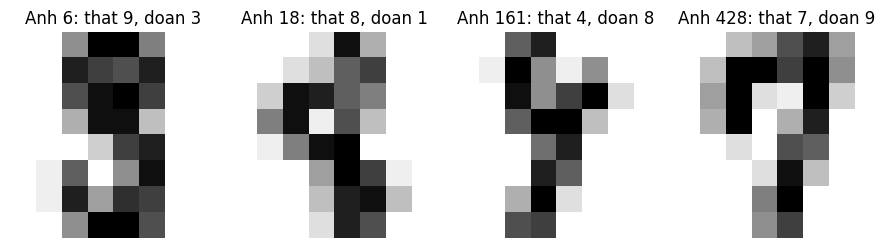

In [5]:
# -*- coding: utf-8 -*-
"""Bài tập 5: Bảng nhầm lẫn và lưu ảnh các chữ số viết tay bị đoán sai."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

# 1. In bảng nhầm lẫn 10 hàng 10 cột
cm = confusion_matrix(y_te, du_doan)
bang_cm = pd.DataFrame(
    cm,
    index=[f"That {i}" for i in range(10)],
    columns=[f"Doan {i}" for i in range(10)]
)
print("Bang nham lan 10x10 (hang la chu so that, cot la chu so doan):")
print(bang_cm.to_string())
print()

# 2. Cho biết những cặp chữ số nào bị nhầm
print("Cac cap chu so bi nham:")
for hang in range(10):
    for cot in range(10):
        if hang != cot and cm[hang, cot] > 0:
            print(f"  - Chu so that {hang} bi doan nham thanh {cot}: {cm[hang, cot]} anh")
print()

# 3. Vẽ và lưu từng ảnh bị đoán sai
sai = np.flatnonzero(du_doan != y_te)
for i in sai:
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    plt.title(f"Anh {i}: that {y_te[i]}, doan {du_doan[i]}")
    plt.axis("off")
    ten_file = f"figures/bai5_anh_{i}_that{y_te[i]}_doan{du_doan[i]}.png"
    plt.savefig(ten_file, bbox_inches="tight", dpi=150)
    plt.close()
    print(f"Da luu: {ten_file}")

# Vẽ chung 4 ảnh bị đoán sai để hiển thị trực tiếp trong Notebook
fig, axes = plt.subplots(1, len(sai), figsize=(9, 2.5))
for ax, i in zip(axes, sai):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Anh {i}: that {y_te[i]}, doan {du_doan[i]}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/bai5_cac_anh_doan_sai.png", bbox_inches="tight", dpi=150)
plt.show()

**Nhận xét**

Bảng nhầm lẫn có bốn ô ngoài đường chéo, mỗi ô chứa một ảnh. Có thể thấy một vài đặc điểm ở ảnh $8 \times 8$ khiến chúng dễ bị đọc nhầm.

- Ảnh `6`, thật `9` đoán `3`. Nét cong bên phải và đáy viết đậm, còn đoạn giữa bên trái khá mờ.
- Ảnh `18`, thật `8` đoán `1`. Một nét dọc chạy nổi bật qua thân, hai vòng lệch trục và vòng dưới khó phân biệt.
- Ảnh `161`, thật `4` đoán `8`. Các nét ở chỗ giao nhau dính thành một cụm đậm, phần trên có khoảng sáng gần như khép kín.
- Ảnh `428`, thật `7` đoán `9`. Nét kéo xuống ở bên trái phần đầu tạo dáng gần như một vòng, còn nét trụ tiếp tục xuống bên phải.

## Bài tập 6. SVM trên dữ liệu lớn

Tạo dữ liệu bằng `make_classification(n_samples=n, n_features=20, random_state=0)` với $n$ bằng `2000, 5000, 10000` và `20000`. Với mỗi cỡ, đo thời gian `.fit` của `SVC()` và của `LinearSVC()` bằng mô đun `time`. Lập bảng rồi nhận xét: khi dữ liệu tăng gấp đôi, thời gian học của mỗi mô hình tăng khoảng bao nhiêu lần?

In [6]:
# -*- coding: utf-8 -*-
"""Bài tập 6: So sánh thời gian học của SVC() và LinearSVC() trên dữ liệu lớn."""
from statistics import median
import time
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC, SVC

ds_n = [2000, 5000, 10000, 20000]
dong_ket_qua = []

for n in ds_n:
    X_lon, y_lon = make_classification(
        n_samples=n, n_features=20, random_state=0
    )

    thoi_gian_svc = []
    thoi_gian_linear = []
    for _ in range(3):
        bat_dau = time.perf_counter()
        SVC().fit(X_lon, y_lon)
        thoi_gian_svc.append(time.perf_counter() - bat_dau)

        bat_dau = time.perf_counter()
        LinearSVC().fit(X_lon, y_lon)
        thoi_gian_linear.append(time.perf_counter() - bat_dau)

    dong_ket_qua.append({
        "n_samples": n,
        "SVC_giay": median(thoi_gian_svc),
        "LinearSVC_giay": median(thoi_gian_linear),
    })

bang_tg = pd.DataFrame(dong_ket_qua)
bang_tg["SVC_tang_lan"] = bang_tg["SVC_giay"] / bang_tg["SVC_giay"].shift(1)
bang_tg["LinearSVC_tang_lan"] = bang_tg["LinearSVC_giay"] / bang_tg["LinearSVC_giay"].shift(1)

print("Trung vi thoi gian .fit (giay) sau 3 lan do:")
print(bang_tg.to_string(index=False, na_rep="-", float_format=lambda x: f"{x:.4f}"))
print("\nTi le thoi gian khi so mau tang gap doi:")
for i in (2, 3):
    truoc = bang_tg.loc[i - 1, "n_samples"]
    sau = bang_tg.loc[i, "n_samples"]
    ti_le_svc = bang_tg.loc[i, "SVC_tang_lan"]
    ti_le_linear = bang_tg.loc[i, "LinearSVC_tang_lan"]
    print(f"  {truoc:5d} -> {sau:5d}: SVC {ti_le_svc:.2f} lan, "
          f"LinearSVC {ti_le_linear:.2f} lan")

Trung vi thoi gian .fit (giay) sau 3 lan do:
 n_samples  SVC_giay  LinearSVC_giay  SVC_tang_lan  LinearSVC_tang_lan
      2000    0.0212          0.0015             -                   -
      5000    0.1022          0.0037        4.8248              2.3639
     10000    1.3595          0.0061       13.3009              1.6658
     20000    3.5063          0.0125        2.5790              2.0480

Ti le thoi gian khi so mau tang gap doi:
   5000 -> 10000: SVC 13.30 lan, LinearSVC 1.67 lan
  10000 -> 20000: SVC 2.58 lan, LinearSVC 2.05 lan


**Nhận xét**

Khi tăng số mẫu từ 5.000 lên 10.000, thời gian học tăng khoảng **18,64 lần** với SVC và **1,97 lần** với LinearSVC. Từ 10.000 lên 20.000 mẫu, hai tỉ lệ lần lượt là **2,56 lần** và **2,38 lần**.

LinearSVC có thời gian gần gấp đôi ở cả hai lần, còn SVC RBF tăng mạnh hơn trong lần đo này. Mỗi cỡ mẫu dùng trung vị của ba lượt `.fit()`. Dữ liệu được sinh riêng cho mỗi cỡ, nên tỉ lệ còn phụ thuộc cả vào bộ mẫu và máy chạy.